# 4. Exploratory Data Analysis (EDA)

## 1. Introduction

Exploratory Data Analysis is used to understand the patterns,
distributions, and relationships within the dataset.

The main objectives are:

- Analyze the target distribution.
- Investigate transaction amounts.
- Explore transaction time.
- Compare fraudulent and legitimate transactions.
- Analyze numerical feature distributions.
- Investigate feature correlations.

EDA findings will help guide feature engineering and model selection.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
    FIGURES_DIR,
)

from src.eda import (
    get_target_distribution,
    get_target_percentage,
    get_numeric_summary,
    get_missing_values,
    plot_target_distribution,
    plot_correlation_matrix,
    plot_amount_distribution,
)

df = pd.read_csv(CLEANED_DATA_PATH)

sns.set_theme(style="whitegrid")

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Target Distribution

The target distribution is examined to understand the level
of class imbalance.

Fraudulent transactions are expected to represent a small
proportion of the dataset.

This imbalance is important because a classifier may achieve
high accuracy simply by predicting the majority class.

,Count,Percentage
Class,,
0,284315,99.827251
1,492,0.172749


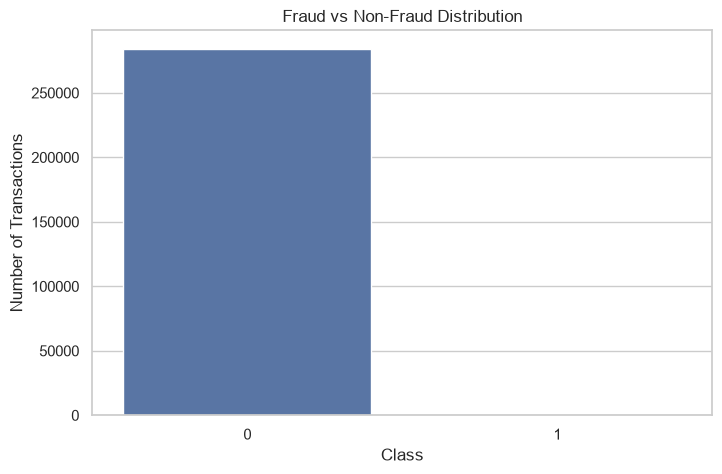

In [15]:
target_counts = get_target_distribution(df)

target_percentages = get_target_percentage(df)

display(
    pd.DataFrame({
        "Count": target_counts,
        "Percentage": target_percentages
    })
)

plot_target_distribution(df)

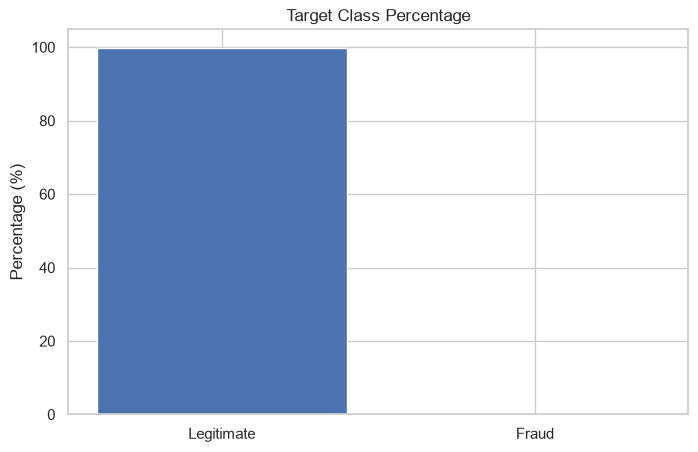

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    [
        target_percentages.get(0, 0),
        target_percentages.get(1, 0)
    ]
)

plt.title("Target Class Percentage")
plt.ylabel("Percentage (%)")

plt.savefig(
    FIGURES_DIR / "target_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Transaction Amount Analysis

The Amount feature represents the monetary value of each transaction.

The distribution is investigated using histograms and boxplots.

Because fraudulent transactions are relatively rare, both
the full dataset and class-specific distributions should
be examined.

Logarithmic visualization may be useful when the distribution
is highly skewed.

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

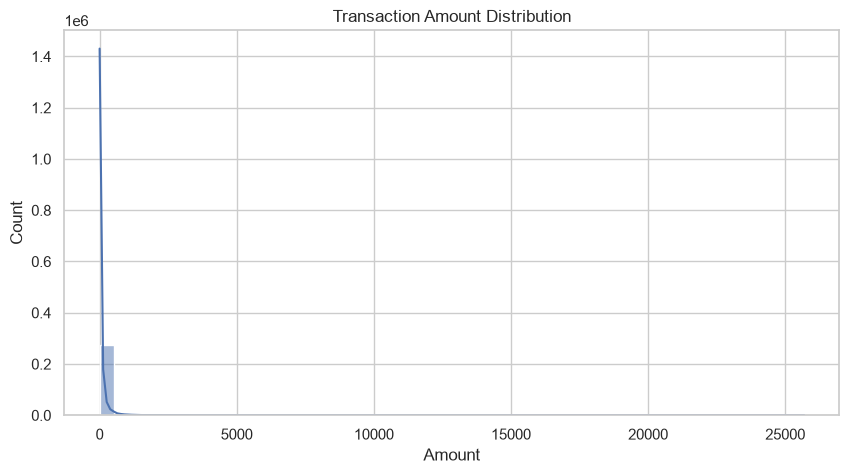

In [17]:
display(
    df["Amount"].describe()
)

plot_amount_distribution(df)

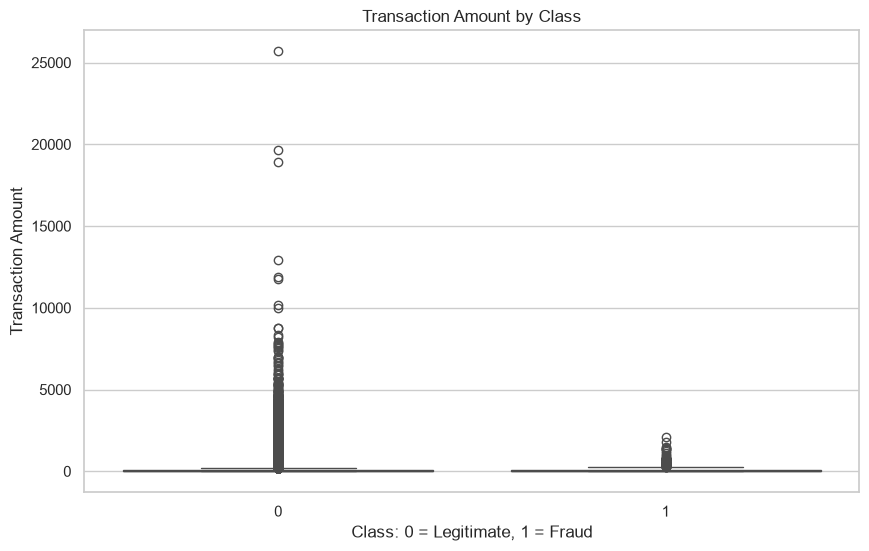

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x=TARGET_COLUMN,
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class: 0 = Legitimate, 1 = Fraud")
plt.ylabel("Transaction Amount")

plt.savefig(
    FIGURES_DIR / "amount_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

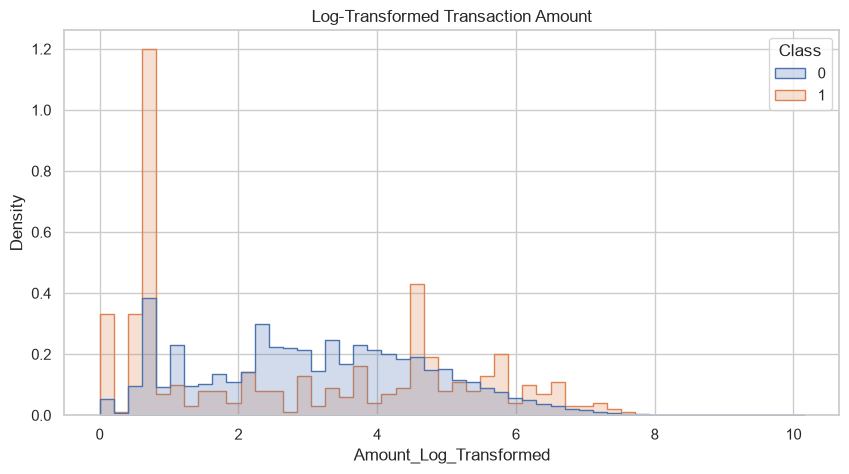

In [19]:
df["Amount_Log_Transformed"] = np.log1p(
    df["Amount"]
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount_Log_Transformed",
    hue=TARGET_COLUMN,
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Log-Transformed Transaction Amount")

plt.savefig(
    FIGURES_DIR / "log_amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Transaction Time Analysis

The Time feature represents elapsed time since the first
transaction in the dataset.

It should not automatically be interpreted as a real-world
timestamp or time of day.

The distribution of Time is investigated to identify
possible temporal patterns.

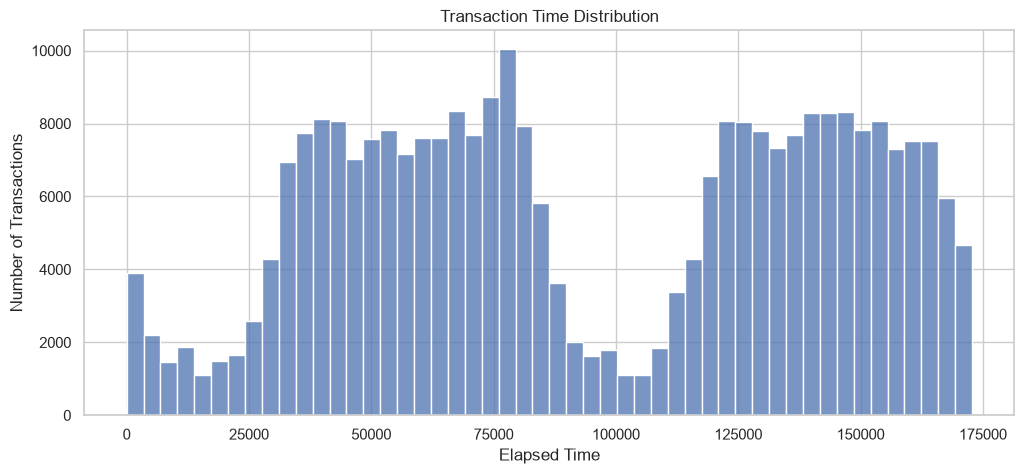

In [20]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    bins=50
)

plt.title("Transaction Time Distribution")
plt.xlabel("Elapsed Time")
plt.ylabel("Number of Transactions")

plt.savefig(
    FIGURES_DIR / "time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

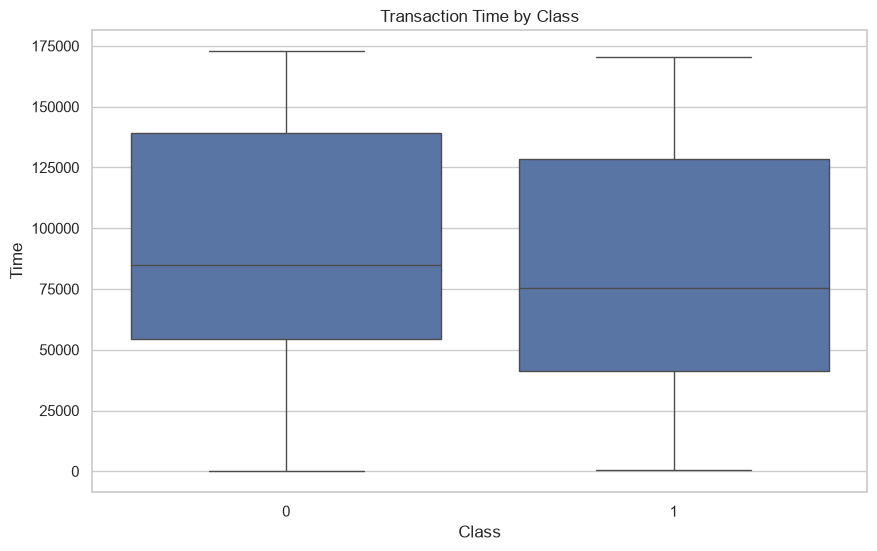

In [21]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x=TARGET_COLUMN,
    y="Time"
)

plt.title("Transaction Time by Class")

plt.savefig(
    FIGURES_DIR / "time_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Numerical Feature Distributions

The anonymized V1 to V28 features are investigated.

These features may contain useful patterns that distinguish
fraudulent transactions from legitimate transactions.

Histograms and class-specific visualizations are used
to explore their distributions.

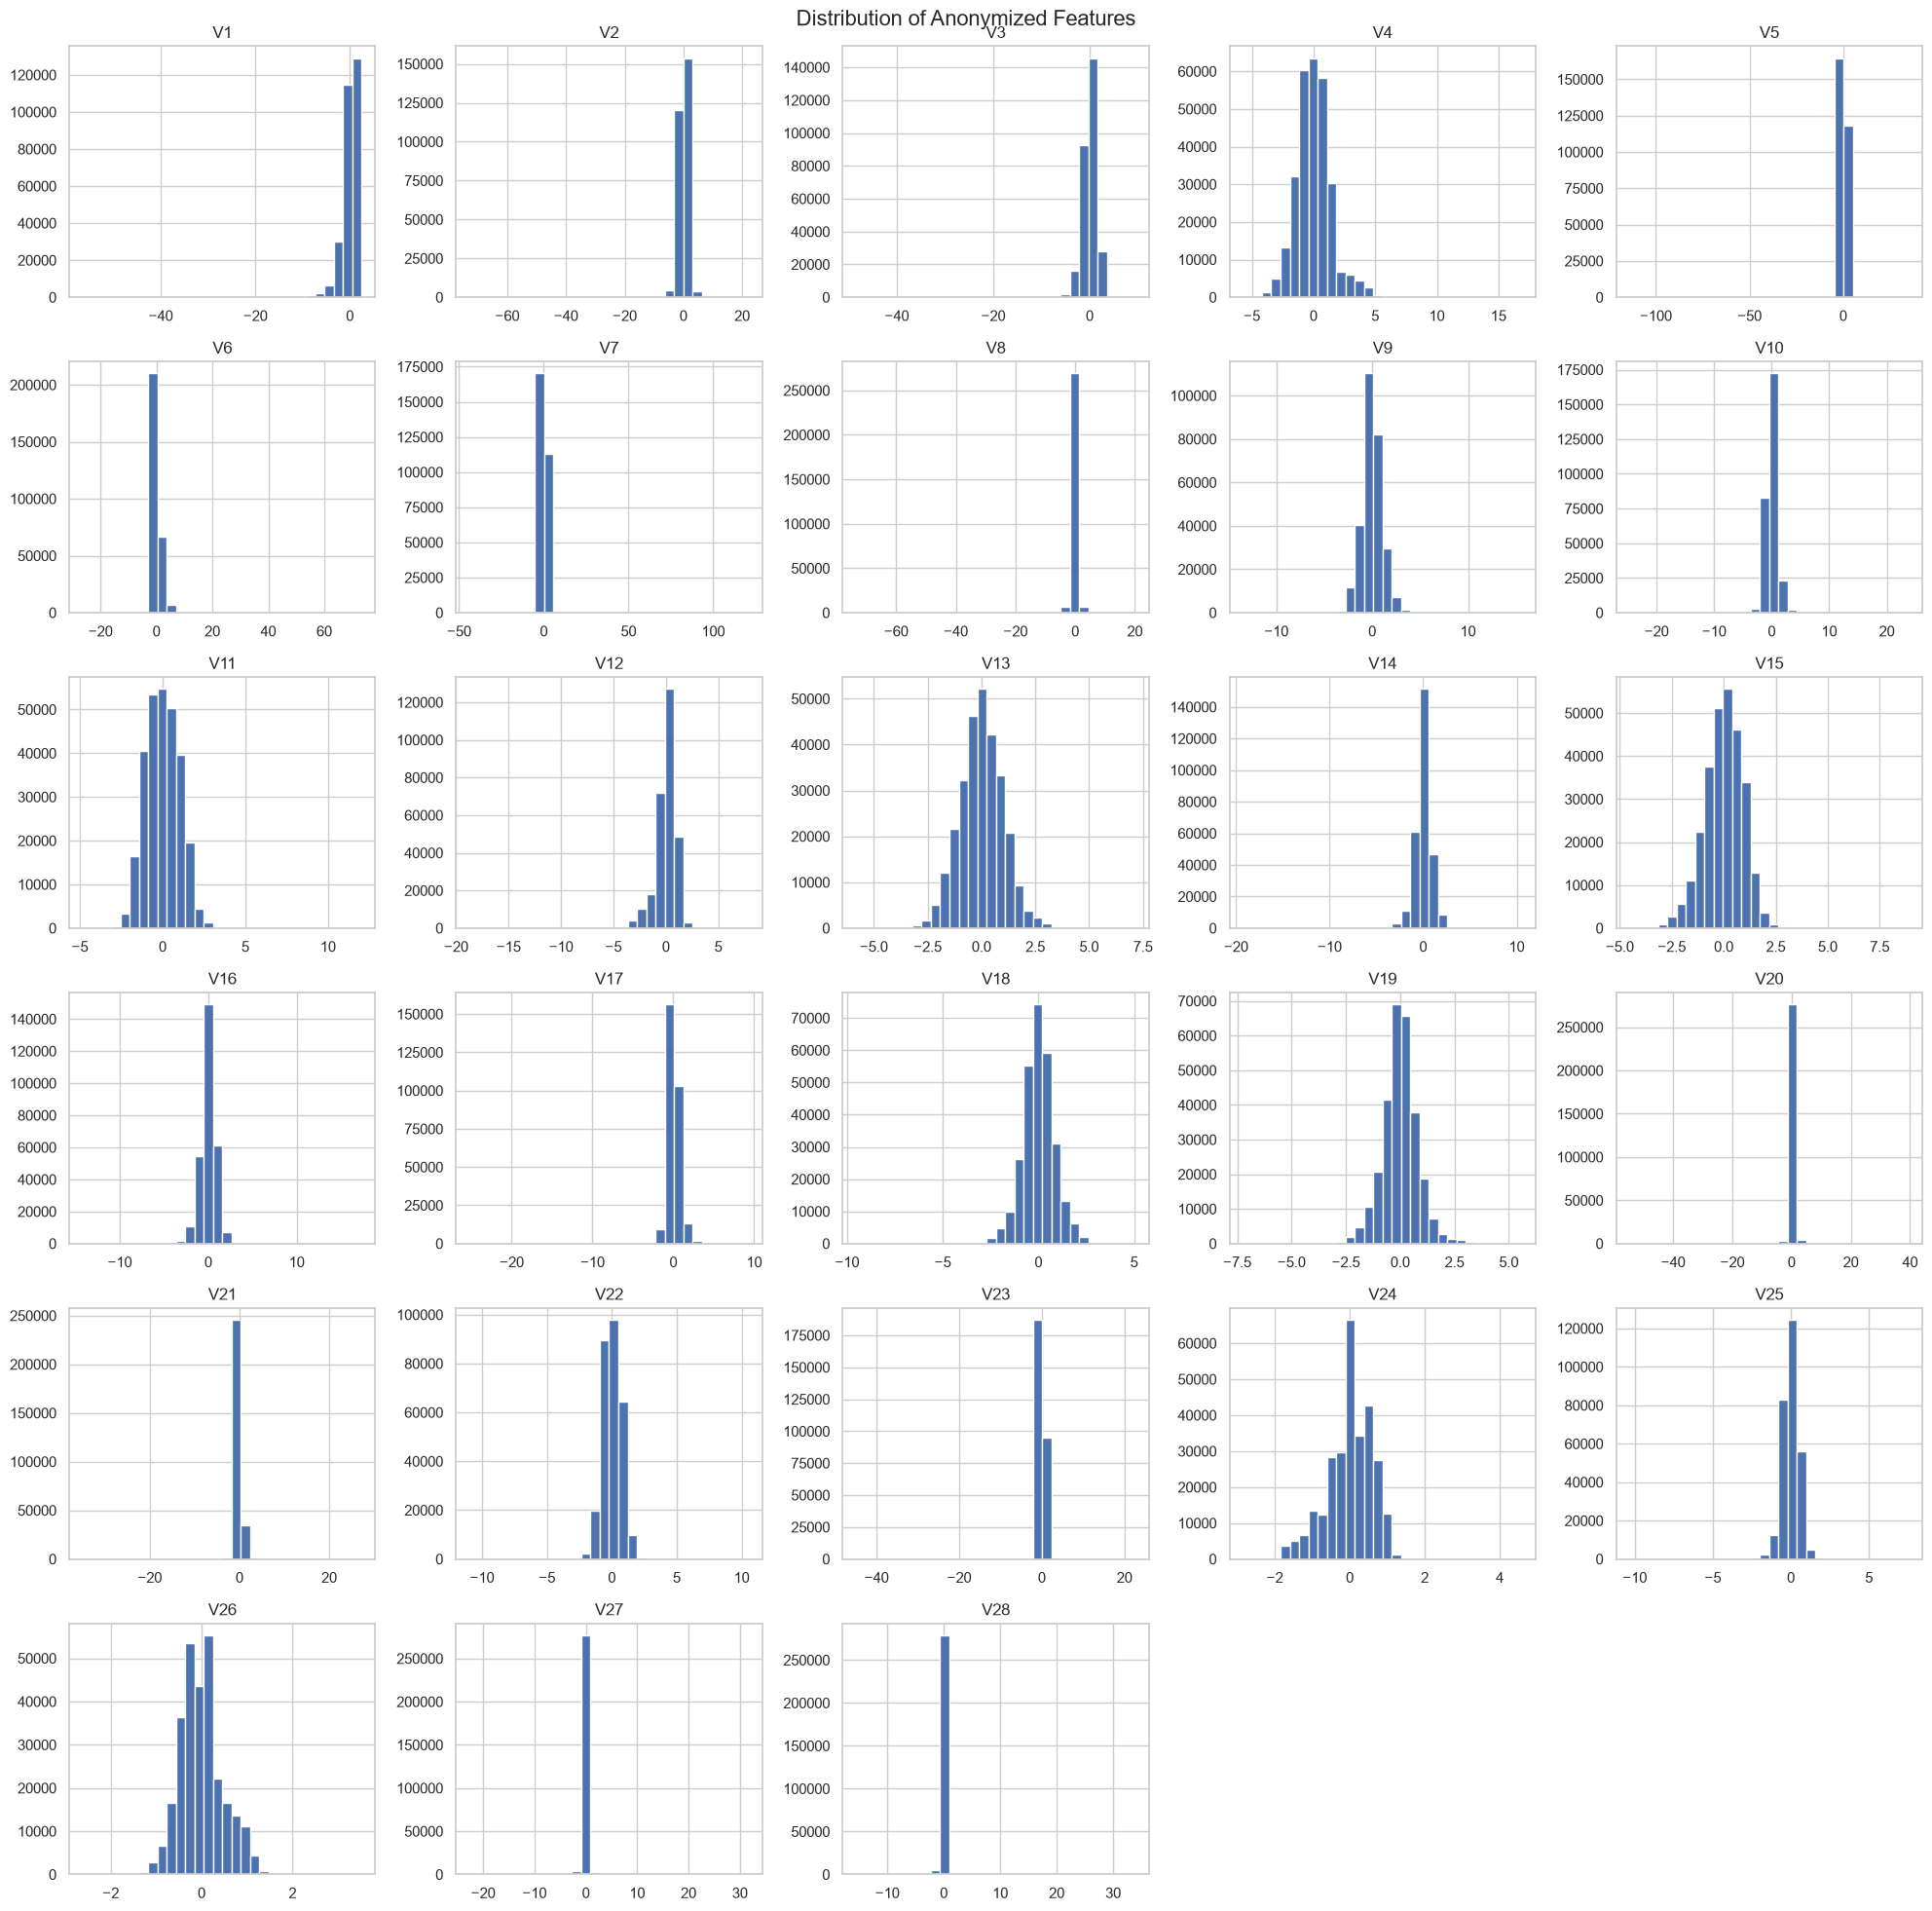

In [22]:
v_columns = [
    f"V{i}"
    for i in range(1, 29)
]

df[v_columns].hist(
    figsize=(20, 20),
    bins=30
)

plt.suptitle(
    "Distribution of Anonymized Features",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "v_features_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

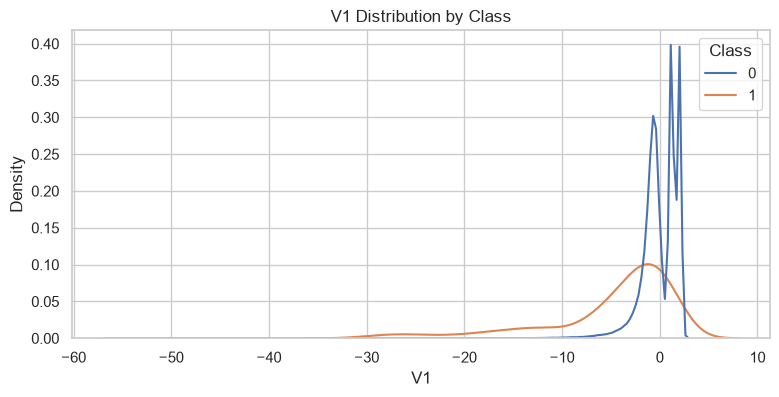

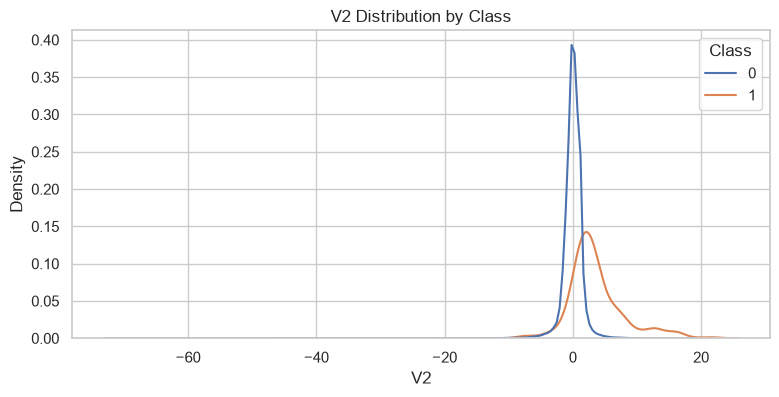

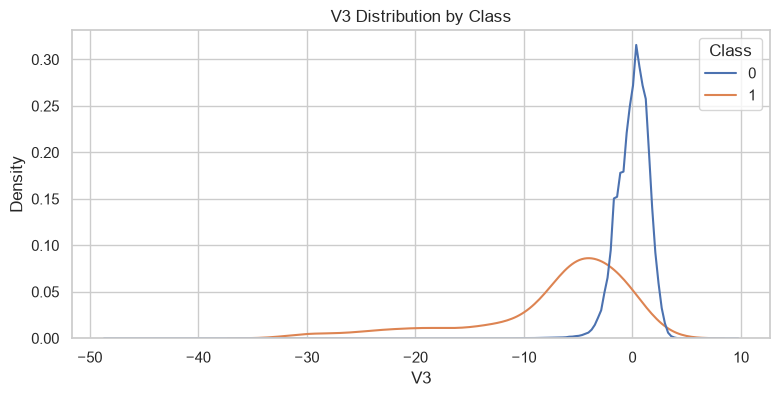

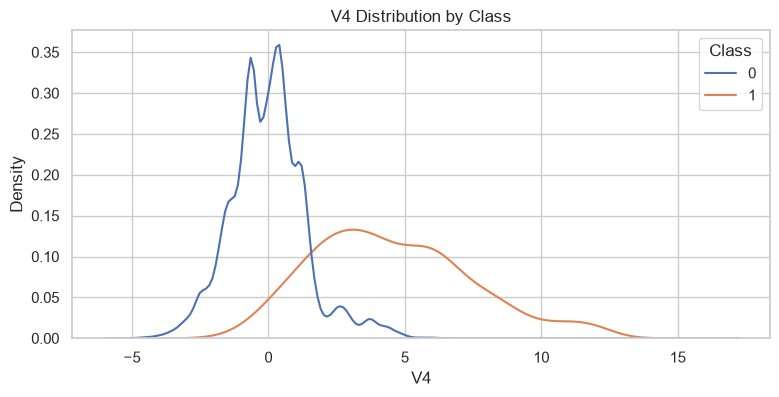

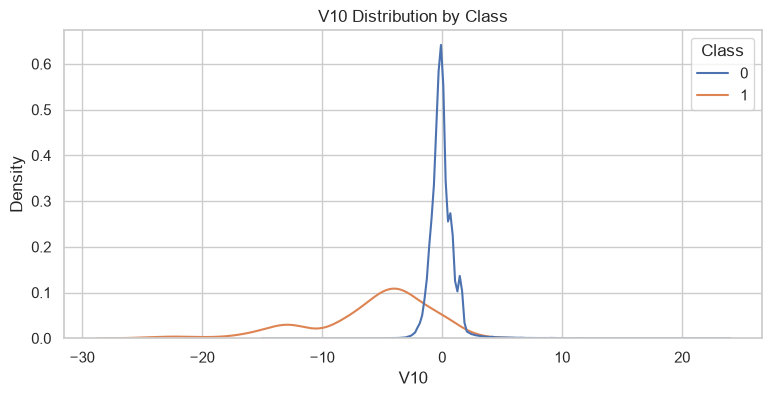

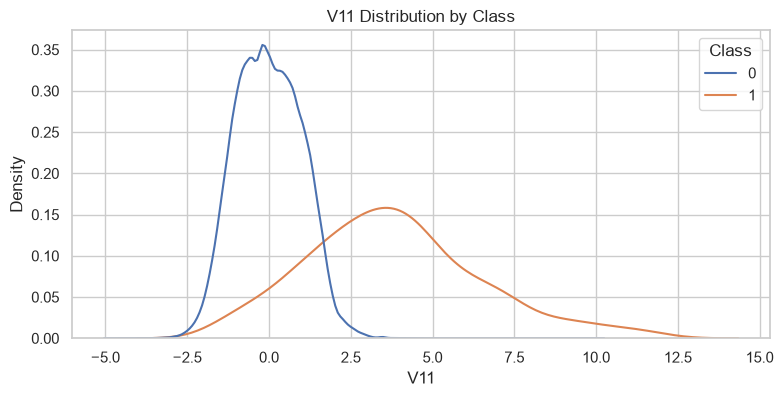

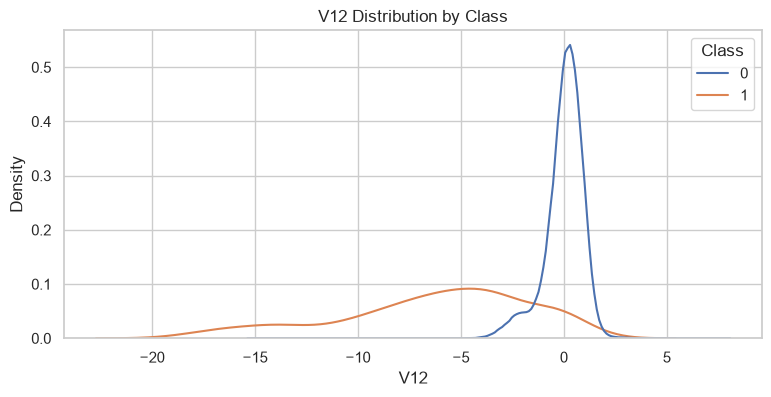

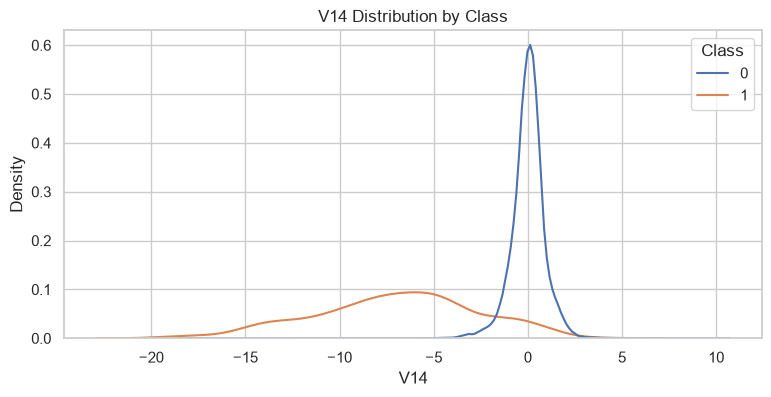

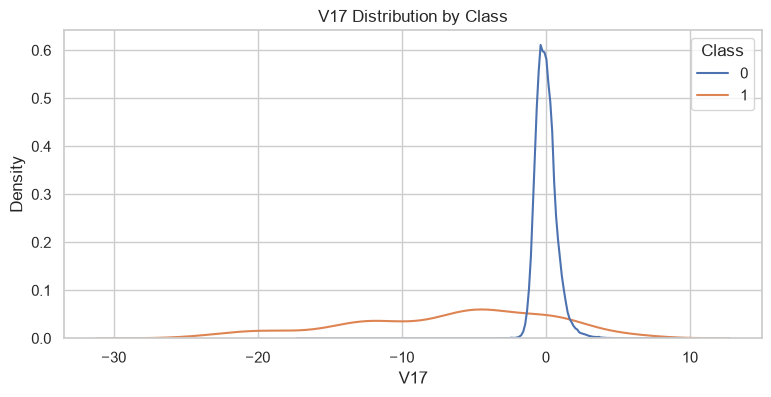

In [23]:
selected_features = [
    "V1",
    "V2",
    "V3",
    "V4",
    "V10",
    "V11",
    "V12",
    "V14",
    "V17",
]

for feature in selected_features:

    plt.figure(figsize=(9, 4))

    sns.kdeplot(
        data=df,
        x=feature,
        hue=TARGET_COLUMN,
        common_norm=False
    )

    plt.title(
        f"{feature} Distribution by Class"
    )

    plt.savefig(
        FIGURES_DIR / f"{feature}_by_class.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 6. Correlation Analysis

Correlation analysis is used to investigate linear relationships
between numerical features.

The correlation between individual features and the target
may provide preliminary insights.

However, correlation does not imply causation, and low
correlation does not necessarily mean that a feature
has no predictive value.

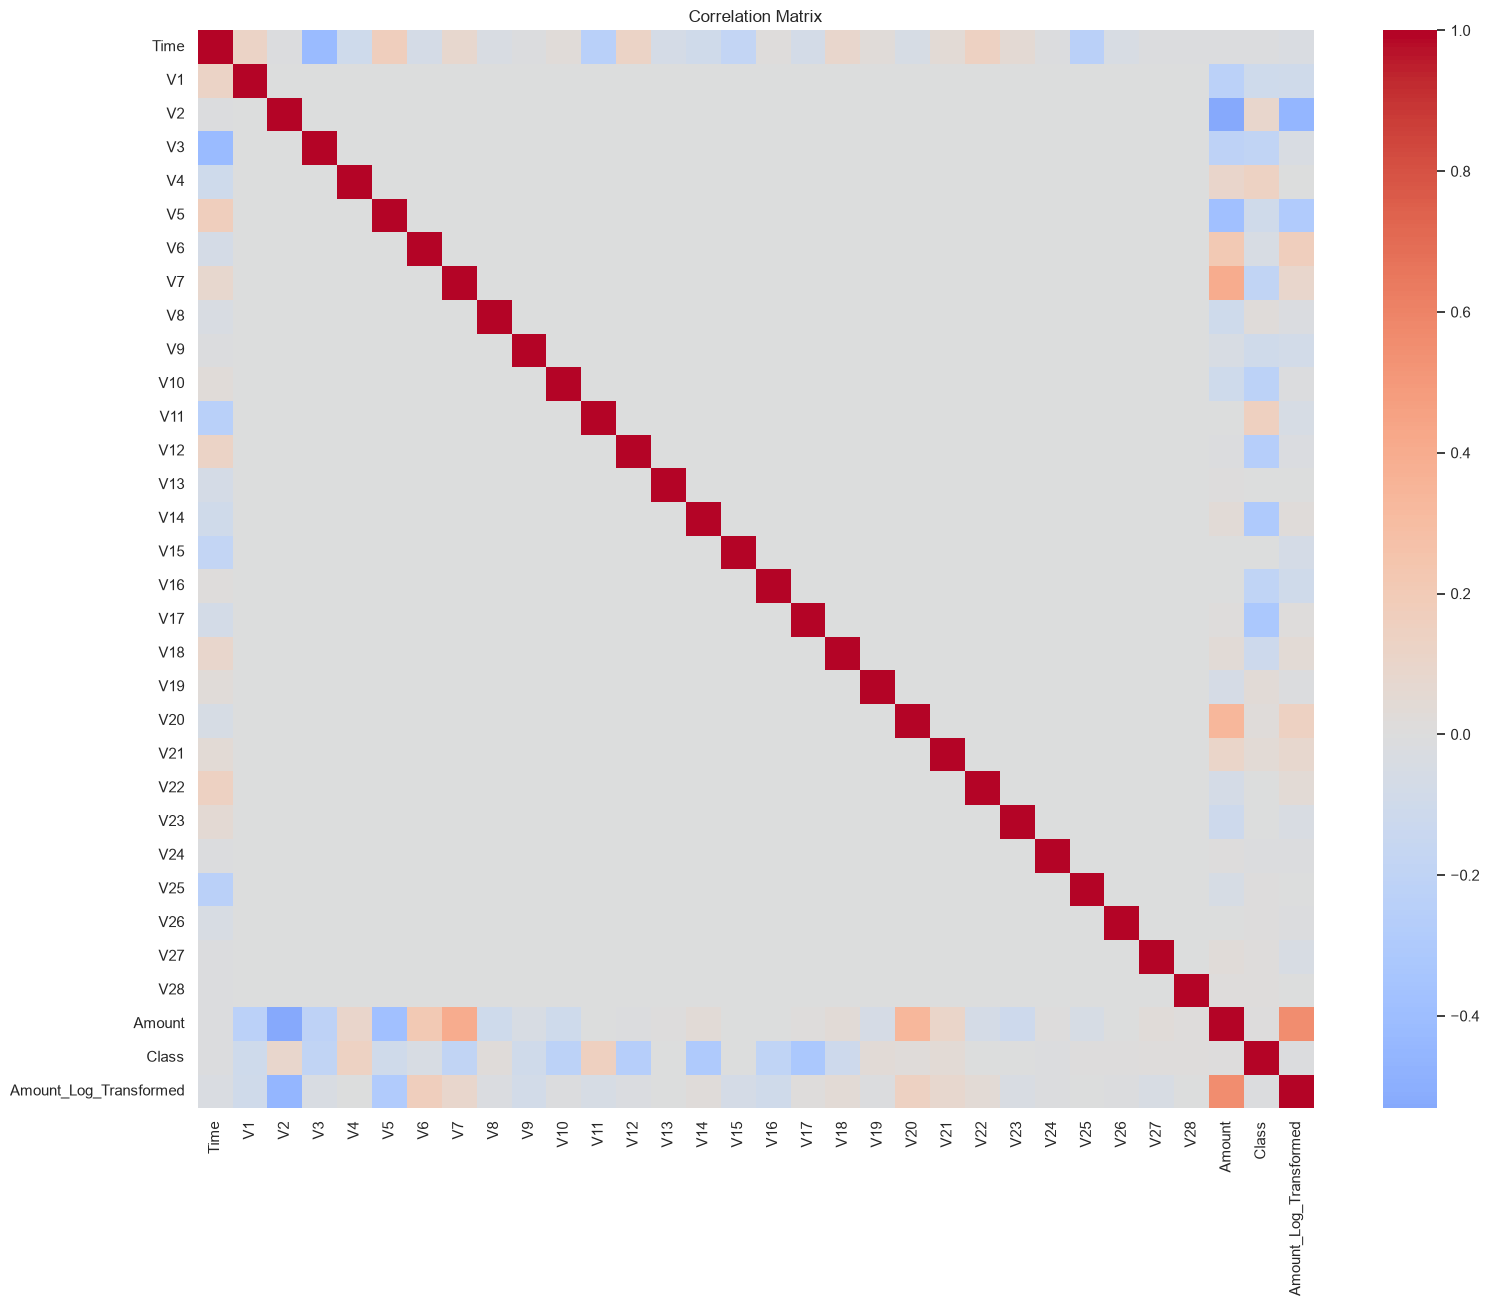

In [24]:
plot_correlation_matrix(df)

,Correlation with Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


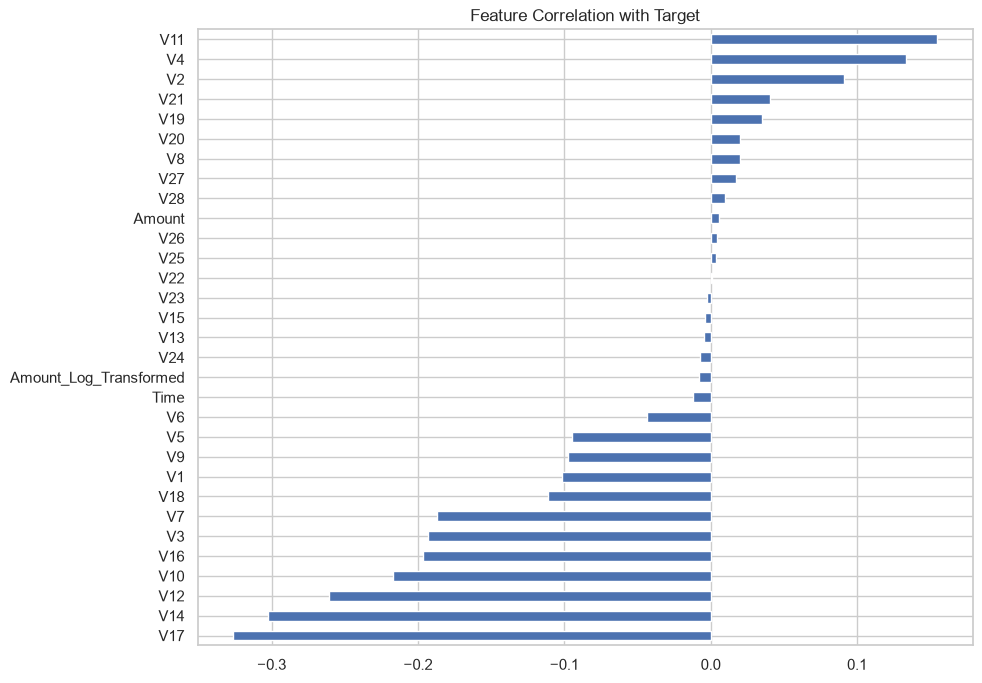

In [25]:
correlation_with_target = (
    df.corr(numeric_only=True)[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values()
)

display(
    correlation_with_target.to_frame(
        name="Correlation with Class"
    )
)

plt.figure(figsize=(10, 8))

correlation_with_target.plot(
    kind="barh"
)

plt.title("Feature Correlation with Target")

plt.savefig(
    FIGURES_DIR / "target_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. EDA Conclusions

After executing the analysis, document the actual findings.

The conclusions should address:

1. The degree of class imbalance.
2. Whether transaction amounts are skewed.
3. Whether transaction time differs between classes.
4. Which anonymized features show noticeable distribution differences.
5. Whether strong feature correlations exist.
6. Which findings may influence feature engineering.

The conclusions must be based on the generated results
rather than assumptions.

In [26]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nTarget Distribution:")
print(get_target_distribution(df))

print("\nTarget Percentage:")
print(get_target_percentage(df))

print("\nAmount Statistics:")
print(df["Amount"].describe())

print("\nTime Statistics:")
print(df["Time"].describe())

print("\nTop Positive Correlations:")
print(
    correlation_with_target
    .sort_values(ascending=False)
    .head(5)
)

print("\nTop Negative Correlations:")
print(
    correlation_with_target
    .sort_values()
    .head(5)
)

EDA SUMMARY

Dataset Shape:
(284807, 32)

Target Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Target Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Amount Statistics:
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Time Statistics:
count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

Top Positive Correlations:
V11    0.154876
V4     0.133447
V2     0.091289
V21    0.040413
V19    0.034783
Name: Class, dtype: float64

Top Negative Correlations:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
